# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Колбасюк Данило'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 5      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 5, файл lr6_варіант_05.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: scikit-learn, shap ...



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: з'ясувати, чи клієнт розірве угоду за таких умов

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: нам потрібно оцінку ризику, поріг, вище якого ми кажемо "розірве угоди", для точності задаємо ми, а AUC робить оцінку незалежно від порогу

CV_SCHEME = 'стратифікована 5-кратна'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: зберігаємо приблизно однакові поділи класів у фолдах

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.289

типи стовпців: {'str': 14, 'float64': 6, 'int64': 6}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
statistics=[]
for col in raw.columns:
    pct_null=raw[col].isnull().mean()*100
    n_unique=raw[col].nunique(dropna=True)
    dtype=str(raw[col].dtype)
    non_null_vals=raw[col].dropna()
    example_val=non_null_vals.iloc[0] if not non_null_vals.empty else None
    statistics.append({
        'стовпець': col,
        'тип': dtype,
        'унікальних': n_unique,
        '% пропусків': pct_null,
        'приклад': example_val
    })
result_table = pd.DataFrame(statistics).sort_values(by='% пропусків', ascending=False).reset_index(drop=True)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print(result_table)

                          стовпець      тип  унікальних  % пропусків     приклад
0                  дата_розірвання      str         284    71.083333  2024-01-01
1             код_причини_закриття      str           5    71.083333      ЯКІ-03
2        середній_час_відповіді_хв  float64         274    31.833333        17.1
3                        трафік_ГБ      str         948     5.000000       170.5
4                щомісячний_платіж      str        1124     4.000000      269.44
5     аварій_на_ділянці_за_квартал  float64           5     3.000000         1.0
6                            стать      str           6     0.000000           ч
7                            місто      str           6     0.000000       Львів
8                       id_клієнта      str        1200     0.000000      K50000
9                              вік  float64          61     0.000000        31.0
10                кількість_послуг    int64           3     0.000000           1
11                      авто

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
text_rows = raw[raw['щомісячний_платіж'].astype(str).str.contains('[а-яА-Яa-zA-Z]', regex=True, na=False)]
print(text_rows[['id_клієнта', 'щомісячний_платіж']].head(),'\n')
date_rows = raw[raw['трафік_ГБ'].astype(str).str.contains('1900|-|:', regex=True, na=False)]
print(date_rows[['id_клієнта', 'трафік_ГБ']].head(),'\n')
mnar_time = raw[raw['кількість_звернень_у_підтримку'] == 0][['id_клієнта', 'кількість_звернень_у_підтримку', 'середній_час_відповіді_хв']]
print("Звернень = 0, але значення часу відповіді є NaN:")
print(mnar_time.head())


    id_клієнта щомісячний_платіж
9       K50009        213.42 грн
163     K50163        235.54 грн
235     K50235        330.13 грн
320     K50320        190.85 грн
367     K50367        207.32 грн 

    id_клієнта            трафік_ГБ
702     K50702  1900-01-03 00:00:00
876     K50876  1900-01-09 00:00:00
914     K50914  1900-01-19 00:00:00 

Звернень = 0, але значення часу відповіді є NaN:
   id_клієнта  кількість_звернень_у_підтримку  середній_час_відповіді_хв
0      K50000                               0                        NaN
1      K50001                               0                        NaN
3      K50003                               0                        NaN
6      K50006                               0                        NaN
10     K50010                               0                        NaN


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'звернень у підтримку не було'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # ----- ВАШ КОД -----
        # 1) None / NaN            -> np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        # 3) число                 -> float
        # 4) текст                 -> перше число в ньому, інакше np.nan
        if pd.isna(v):
            return np.nan
        if isinstance(v,(pd.Timestamp, datetime.datetime, datetime.date)):
            return np.nan
        if isinstance(v,(int,float,np.number)) and not isinstance(v,bool):
            return float(v)
        if isinstance(v,str):
            match = re.search(r'[-+]?\d+(?:[.,]\d+)?', v)
            if match:
                num_str = match.group(0).replace(',', '.')
                try:
                    return float(num_str)
                except ValueError:
                    return np.nan
            return np.nan
        return np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        # ----- ВАШ КОД -----
        # дата_підключення -> число (день);
        # текстова колонка, де >80% значень розбираються в число -> число;
        # інша текстова -> category (не забудьте привести регістр і пробіли);
        # числова -> float
        col_data=d[c]
        if c=='дата_підключення':
            dt=pd.to_datetime(col_data, errors='coerce')
            X[c]=dt.dt.day.astype(float)
            log.append({
                'стовпець': c,
                'початковий тип': str(col_data.dtype),
                'цільовий тип': 'число (день)',
                'дія': 'отримали число дня'
            })
        elif col_data.dtype=='object' or isinstance(col_data.dtype, pd.StringDtype):
            parsed_num=to_number(col_data)
            non_null_count=col_data.dropna().count()
            success_rate=(parsed_num.dropna().count()/non_null_count) if non_null_count > 0 else 0.0
            if success_rate>0.8:
                X[c]=parsed_num.astype(float)
                log.append({
                    'стовпець': c,
                    'початковий тип': str(col_data.dtype),
                    'цільовий тип': 'число',
                    'дія': 'отримали з текстового стовпця, в якому >80% значень розбираються в число'
                })
            else:
                cleaned_text=col_data.astype(str).str.strip().str.lower()
                cleaned_text=cleaned_text.where(col_data.notna(), np.nan)
                X[c]=cleaned_text.astype('category')
                log.append({
                    'стовпець': c,
                    'початковий тип': str(col_data.dtype),
                    'цільовий тип': 'категорія',
                    'дія': 'приведено до нижнього регістру та прибрано пробіли'
                })
        else:
            X[c]=col_data.astype(float)
            log.append({
                'стовпець': c,
                'початковий тип': str(col_data.dtype),
                'цільовий тип': 'float',
                'дія': 'переведено до float'
            })
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 6


,стовпець,початковий тип,цільовий тип,дія
0,вік,float64,float,переведено до float
1,стать,str,категорія,приведено до нижнього регістру та прибрано про...
2,місто,str,категорія,приведено до нижнього регістру та прибрано про...
3,філія,str,число,"отримали з текстового стовпця, в якому >80% зн..."
4,тариф,str,категорія,приведено до нижнього регістру та прибрано про...
5,тип_підключення,str,категорія,приведено до нижнього регістру та прибрано про...
6,спосіб_оплати,str,категорія,приведено до нижнього регістру та прибрано про...
7,автоплатіж,str,категорія,приведено до нижнього регістру та прибрано про...
8,кількість_послуг,int64,float,переведено до float
9,місяців_обслуговування,float64,float,переведено до float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    num_cols=X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat_cols=X.select_dtypes(include=['category', 'object']).columns.tolist()
    num_transformer=Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_transformer=Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    preprocessor=ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ]
    )
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.916


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.918 ± 0.027
час      : 1.0 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'або задача проста, або є витік'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

або задача проста, або є витік


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        # ----- ВАШ КОД -----
        # підказка: показник = roc_auc_score(y, d[c].notna().astype(int)),
        # але рахувати його можна лише якщо обидві групи більші за min_group
        mask_notna=d[c].notna()
        n_filled=mask_notna.sum()
        n_missing=len(d)-n_filled
        churn_rate_filled=y[mask_notna].mean() if n_filled > 0 else np.nan
        churn_rate_missing=y[~mask_notna].mean() if n_missing > 0 else np.nan
        if n_filled>=min_group and n_missing>=min_group:
            filled_flag=mask_notna.astype(int)
            auc=roc_auc_score(y, filled_flag)
            score=max(auc, 1-auc)
        else:
            score = np.nan
        rows.append({
            'ознака': c,
            'заповнено': n_filled,
            'частка_відтоку_де_заповнено': round(churn_rate_filled, 4) if pd.notna(churn_rate_filled) else np.nan,
            'частка_відтоку_де_пропуск': round(churn_rate_missing, 4) if pd.notna(churn_rate_missing) else np.nan,
            'показник': round(score, 4) if pd.notna(score) else np.nan
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))


,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,347,1.0000,0.0000,1.0000
23,дата_розірвання,347,1.0000,0.0000,1.0000
17,середній_час_відповіді_хв,818,0.3227,0.2173,0.5557
14,трафік_ГБ,1140,0.2833,0.4000,0.5135
12,щомісячний_платіж,1152,0.2839,0.4167,0.5124
16,аварій_на_ділянці_за_квартал,1164,0.2904,0.2500,0.5029
0,id_клієнта,1200,0.2892,NaN,NaN
1,вік,1200,0.2892,NaN,NaN
2,стать,1200,0.2892,NaN,NaN
3,місто,1200,0.2892,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    # 'назва_стовпця',   # чому його немає в момент прогнозу
    'код_причини_закриття', # якщо є записаний код, то відповідно вже знаємо, що було закриття
    'дата_розірвання' # так само, якщо є записана дата, то вже ясно, що угода була розірвана 
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.904 ± 0.021


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']


In [18]:
HUMAN_LEAK = [
    # 'назва_стовпця',   # ким і КОЛИ заповнюється це поле
    'кількість_дзвінків_утримання' # заповнюється оператором під час або після спроби утримання
]
HUMAN_LEAK_WHY = 'детектор перевіряє, чи сам факт заповненості передбачає клас. Для цього стовпця всі значення заповнені, тому його не було спіймано'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.829 ± 0.031


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [19]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
# Шукайте СХОДИНКУ, а не плавну зміну.
branch_stats = raw.groupby('філія').agg(
    всього_клієнтів=('відтік', 'count'),
    кількість_відтоку=('відтік', 'sum'),
    частка_відтоку=('відтік', 'mean')
).reset_index()
branch_stats['частка_відтоку_%'] = (branch_stats['частка_відтоку'] * 100).round(2)
branch_stats = branch_stats.sort_values(by='частка_відтоку', ascending=False).reset_index(drop=True)
raw['квартал_підключення'] = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
quarter_stats = raw.groupby('квартал_підключення').agg(
    всього_клієнтів=('відтік', 'count'),
    кількість_відтоку=('відтік', 'sum'),
    частка_відтоку=('відтік', 'mean')
).reset_index()
quarter_stats['частка_відтоку_%'] = (quarter_stats['частка_відтоку'] * 100).round(2)
print(branch_stats[['філія', 'всього_клієнтів', 'кількість_відтоку', 'частка_відтоку_%']])#
print(quarter_stats[['квартал_підключення', 'всього_клієнтів', 'кількість_відтоку', 'частка_відтоку_%']])


            філія  всього_клієнтів  кількість_відтоку  частка_відтоку_%
0  Ф-06 Приміська              215                 67             31.16
1    Ф-04 Південь              194                 60             30.93
2     Ф-05 Північ              213                 62             29.11
3      Ф-02 Захід              185                 53             28.65
4      Ф-01 Центр              199                 55             27.64
5       Ф-03 Схід              194                 50             25.77
  квартал_підключення  всього_клієнтів  кількість_відтоку  частка_відтоку_%
0              2023Q1              164                 28             17.07
1              2023Q2              156                 34             21.79
2              2023Q3              143                 27             18.88
3              2023Q4              140                 28             20.00
4              2024Q1              155                 43             27.74
5              2024Q2              131  

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
if 'квартал_підключення' in raw.columns:
    raw = raw.drop(columns=['квартал_підключення'])
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
dates = pd.to_datetime(raw['дата_підключення'])
source = (dates >= '2024-04-01').astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.805
ті самі ознаки передбачають ВІДТІК  : AUC 0.827 ± 0.032


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.918
2. мінус цільовий витік,22,0.904
3. мінус оцінки людини,21,0.829
4. мінус артефакт збору,20,0.827


чесне число: 0.827 ± 0.032


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'залишити'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'я думаю, що цю ознаку можна перетворити на декілька корисніших ознак, наприклад кількість місяців обслуговування'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити — я думаю, що цю ознаку можна перетворити на декілька корисніших ознак, наприклад кількість місяців обслуговування


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=SEED),   # ----- ВАШ КОД -----
    'випадковий ліс':       RandomForestClassifier(n_estimators=100, random_state=SEED),   # ----- ВАШ КОД -----
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),   # ----- ВАШ КОД -----
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.827,0.032,1.1
одне дерево,0.638,0.032,0.8
випадковий ліс,0.829,0.019,4.9
гістограмний бустинг,0.824,0.022,4.7


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy.stats import t as t_dist
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    # ----- ВАШ КОД -----
    diff=np.array(b)-np.array(a)
    mean_diff=np.mean(diff)
    n=len(diff)
    std_err=np.std(diff, ddof=1)/np.sqrt(n)
    t_crit = t_dist.ppf(0.975, df=n - 1)
    h=t_crit*std_err
    return mean_diff,h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0024 ± 0.0092   у межах шуму
гістограмний бустинг   проти логістичної: -0.0032 ± 0.0116   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'AUC в межах допустимого для якісної моделі з малим часом на 100 навчань'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — AUC в межах допустимого для якісної моделі з малим часом на 100 навчань


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    F['ціна_за_мб']=F['щомісячний_платіж']/(F['швидкість_тарифу_Мбіт']+1e-5) # ті, хто платять забагато за одиницю швидкості порівняно зі стандартною ціною ринку, можуть бути стимульовані знайти кращі (дешевші) варіанти
    F['звернень_за_місяць']=F['кількість_звернень_у_підтримку']/(F['місяців_обслуговування']+1.0) # ті, хто мають багато звернень в підтримку можуть бути незадоволені теперішнім провайдером
    F['немає_знижки']=(F['знижка_відсоток']==0).astype(float) # ті, хто платять повну ціну, більш ймовірно будуть шукати пропозиції з дешевшими цінами
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.825 ± 0.031
приріст проти базового набору: -0.0015 ± 0.0019   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Складніша модель дала трохи більше, але витратила набагато більше часу (4.5-6.3с для 100 навчань)'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Складніша модель дала трохи більше, але витратила набагато більше часу (4.5-6.3с для 100 навчань)


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.813
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

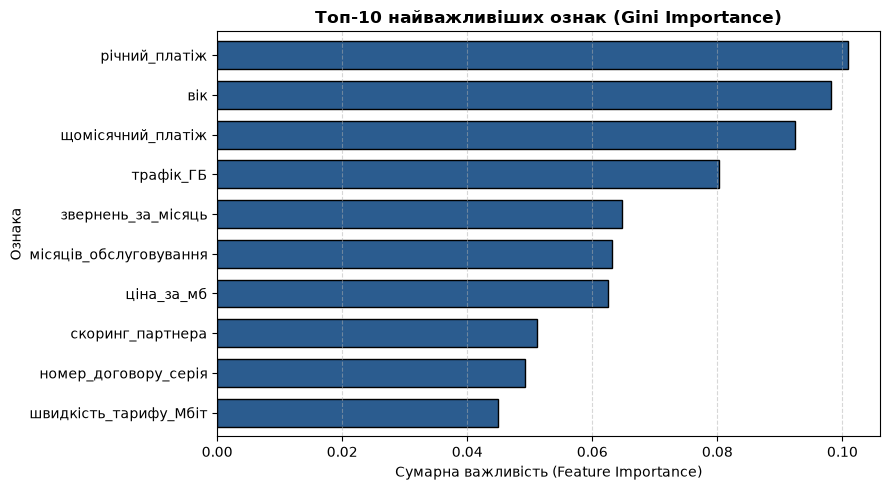

In [30]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
prep=model.named_steps['preprocessor']
rf_clf=model.named_steps['classifier']
feature_names=prep.get_feature_names_out()
importances=rf_clf.feature_importances_
aggregated_imp={}
for name,imp in zip(feature_names,importances):
    clean_name=name.split('__', 1)[-1]
    matched_col=None
    for orig_col in FINAL_X.columns:
        if clean_name==orig_col or clean_name.startswith(orig_col+'_'):
            matched_col=orig_col
            break
    if matched_col is None:
        matched_col=clean_name
    aggregated_imp[matched_col]=aggregated_imp.get(matched_col,0.0)+imp
gini_imp = pd.Series(aggregated_imp).sort_values(ascending=True)
plt.figure(figsize=(9, 5))
top10=gini_imp.tail(10)
top10.plot(kind='barh', color='#2b5c8f', edgecolor='black', width=0.7)
plt.title('Топ-10 найважливіших ознак (Gini Importance)', fontsize=12, fontweight='bold')
plt.xlabel('Сумарна важливість (Feature Importance)', fontsize=10)
plt.ylabel('Ознака', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.055657
трафік_ГБ,0.040623
звернень_за_місяць,0.025364
річний_платіж,0.023854
місяців_обслуговування,0.023712
щомісячний_платіж,0.013200
ціна_за_мб,0.007289
аварій_на_ділянці_за_квартал,0.004118
швидкість_тарифу_Мбіт,0.003313
кількість_послуг,0.000665


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
cmp_imp = pd.DataFrame({
    'вбудована (Gini)': gini_imp,
    'перестановочна (Permutation)': perm_imp
}).sort_values('вбудована (Gini)', ascending=False)
display(cmp_imp)
top5_gini = cmp_imp.head(5)

,вбудована (Gini),перестановочна (Permutation)
річний_платіж,0.100962,0.023854
вік,0.098200,0.055657
щомісячний_платіж,0.092409,0.013200
трафік_ГБ,0.080286,0.040623
звернень_за_місяць,0.064767,0.025364
місяців_обслуговування,0.063178,0.023712
ціна_за_мб,0.062538,0.007289
скоринг_партнера,0.051211,-0.004624
номер_договору_серія,0.049225,-0.001116
швидкість_тарифу_Мбіт,0.044919,0.003313


In [33]:
FAKE_IMPORTANT = 'щомісячний_платіж'        # назва ознаки
FAKE_IMPORTANT_WHY = 'має високу кардинальність, модель перенавчається на тренувальній вибірці'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: щомісячний_платіж


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = FINAL_X.select_dtypes(include=[np.number]).columns
corr_matrix = FINAL_X[num_cols].corr()
high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        col1, col2 = num_cols[i], num_cols[j]
        r = corr_matrix.loc[col1, col2]
        if abs(r) > 0.97:
            high_corr_pairs.append((col1, col2, round(r, 4)))
print("Знайдена пара ознак-дублікатів (|r| > 0.97):", high_corr_pairs)

Знайдена пара ознак-дублікатів (|r| > 0.97): [('щомісячний_платіж', 'річний_платіж', np.float64(0.9991))]


In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
col_keep = DUP_PAIR[0]
col_drop = DUP_PAIR[1]
Xtr_no_dup = Xtr.drop(columns=[col_drop])
Xte_no_dup = Xte.drop(columns=[col_drop])
model_no_dup=make_pipe(Xtr_no_dup, FINAL_CLF).fit(Xtr_no_dup, ytr)
perm_no_dup=permutation_importance(model_no_dup, Xte_no_dup, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_no_dup = pd.Series(perm_no_dup.importances_mean, index=Xtr_no_dup.columns)
print(f"\nу моделі без '{col_drop}':")
print('   %-28s %+.4f' % (col_keep, perm_imp_no_dup[col_keep]))

у повній моделі:
   щомісячний_платіж            +0.0132
   річний_платіж                +0.0239

у моделі без 'річний_платіж':
   щомісячний_платіж            +0.0406


In [36]:
DUP_EXPLANATION = 'перестановочна важливість вказує наскільки модель погіршиться без певної ознаки, а в повній моделі в нас є два стовпчики з однаковою інформацією'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

перестановочна важливість вказує наскільки модель погіршиться без певної ознаки, а в повній моделі в нас є два стовпчики з однаковою інформацією


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

Три найважливіші числові ознаки: ['вік', 'трафік_ГБ', 'звернень_за_місяць']


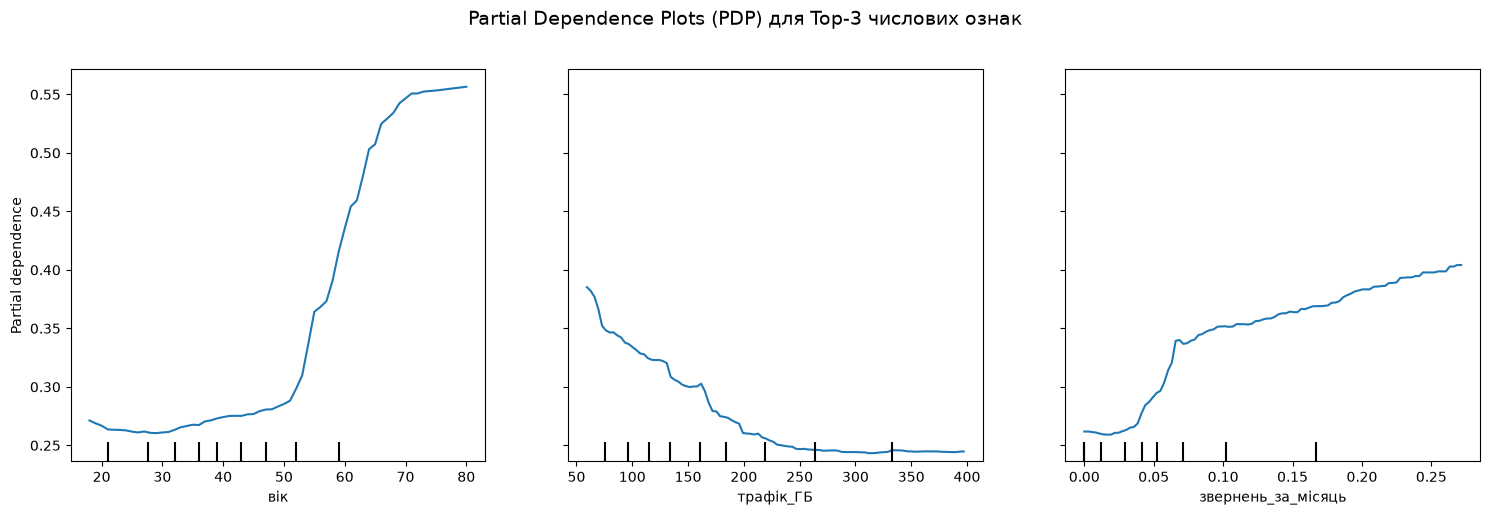

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
# PartialDependenceDisplay.from_estimator(model, Xte, features=[...], kind='average')
# Увага: ознака з пропусками дасть порожню сітку — беріть ознаки без NaN
# або будуйте PDP на підвибірці, де ця ознака заповнена.
model = make_pipe(FINAL_X, FINAL_CLF)
model.fit(Xtr, ytr)

numeric_cols = FINAL_X.select_dtypes(include=[np.number]).columns
top3_numeric = perm_imp[perm_imp.index.isin(numeric_cols)].head(3).index.tolist()
print("Три найважливіші числові ознаки:", top3_numeric)
X_pdp = Xte.dropna(subset=top3_numeric)

fig, ax = plt.subplots(figsize=(15, 5))
disp=PartialDependenceDisplay.from_estimator(
    estimator=model,
    X=X_pdp,
    features=['вік', 'трафік_ГБ', 'звернень_за_місяць'],
    kind='average',
    ax=ax
)
plt.suptitle('Partial Dependence Plots (PDP) для Top-3 числових ознак', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

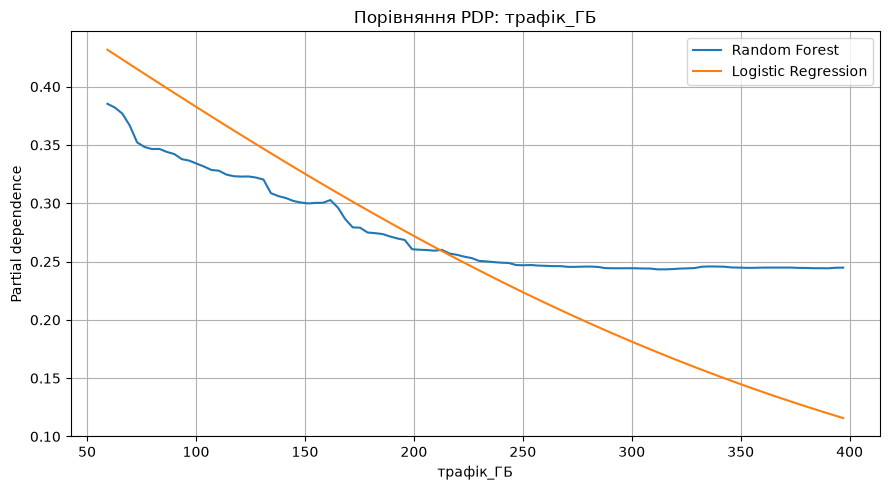

In [38]:
NONLINEAR_FEATURE = 'трафік_ГБ'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
log_model = make_pipe(
    FINAL_X,
    LogisticRegression(max_iter=2000, random_state=SEED)
)

log_model.fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(9, 5))

# PDP випадкового лісу
rf_display = PartialDependenceDisplay.from_estimator(
    model,
    X_pdp,
    features=[NONLINEAR_FEATURE],
    kind='average'
)

# Копіюємо координати першої кривої
rf_line = rf_display.lines_[0, 0]
x_rf = rf_line.get_xdata()
y_rf = rf_line.get_ydata()

plt.close(rf_display.figure_)

# PDP логістичної регресії
lr_display = PartialDependenceDisplay.from_estimator(
    log_model,
    X_pdp,
    features=[NONLINEAR_FEATURE],
    kind='average'
)

lr_line = lr_display.lines_[0, 0]
x_lr = lr_line.get_xdata()
y_lr = lr_line.get_ydata()

plt.close(lr_display.figure_)

# Обидві криві на одному графіку
ax.plot(x_rf, y_rf, label='Random Forest')
ax.plot(x_lr, y_lr, label='Logistic Regression')

ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('Partial dependence')
ax.set_title(f'Порівняння PDP: {NONLINEAR_FEATURE}')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

In [39]:
NONLINEAR_MEANING = 'після використання трафіку 250ГБ користувачі зазвичай не розривають угоду, але шанс цього залишається фіксованим'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'обрізання за порогом'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

після використання трафіку 250ГБ користувачі зазвичай не розривають угоду, але шанс цього залишається фіксованим
обрізання за порогом


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
# 2) додайте ознаку «квадрат відхилення від цього значення»;
# 3) парне порівняння логістичної регресії з нею і без неї.
from sklearn.model_selection import StratifiedKFold
CENTER_VALUE = 250.0
X5_engineered = FINAL_X.copy()
X5_engineered['трафік_ГБ_sq_diff'] = (X5_engineered['трафік_ГБ'] - CENTER_VALUE) ** 2
clf_base = LogisticRegression(max_iter=1000, random_state=SEED)
clf_new = LogisticRegression(max_iter=1000, random_state=SEED)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
auc_base_list = []
auc_new_list = []
for train_idx, val_idx in skf.split(FINAL_X, y):
    X_tr_b, X_va_b = FINAL_X.iloc[train_idx], FINAL_X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
    pipe_base = make_pipe(X_tr_b, clf_base).fit(X_tr_b, y_tr)
    auc_base_list.append(roc_auc_score(y_va, pipe_base.predict_proba(X_va_b)[:, 1]))
    X_tr_n, X_va_n = X5_engineered.iloc[train_idx], X5_engineered.iloc[val_idx]
    pipe_new = make_pipe(X_tr_n, clf_new).fit(X_tr_n, y_tr)
    auc_new_list.append(roc_auc_score(y_va, pipe_new.predict_proba(X_va_n)[:, 1]))

mean_auc_base = np.mean(auc_base_list)
mean_auc_new = np.mean(auc_new_list)
diff_auc = mean_auc_new - mean_auc_base

print(f"Базова Логістична Регресія (без ознаки): Mean AUC = {mean_auc_base:.4f}")
print(f"Модифікована Логістична Регресія (з ознакою): Mean AUC = {mean_auc_new:.4f}")
print(f"Приріст якості (ΔAUC): {diff_auc:+.4f}")

Базова Логістична Регресія (без ознаки): Mean AUC = 0.8227
Модифікована Логістична Регресія (з ознакою): Mean AUC = 0.8233
Приріст якості (ΔAUC): +0.0006


In [41]:
QUAD_GAIN = 0.0006     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0006


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

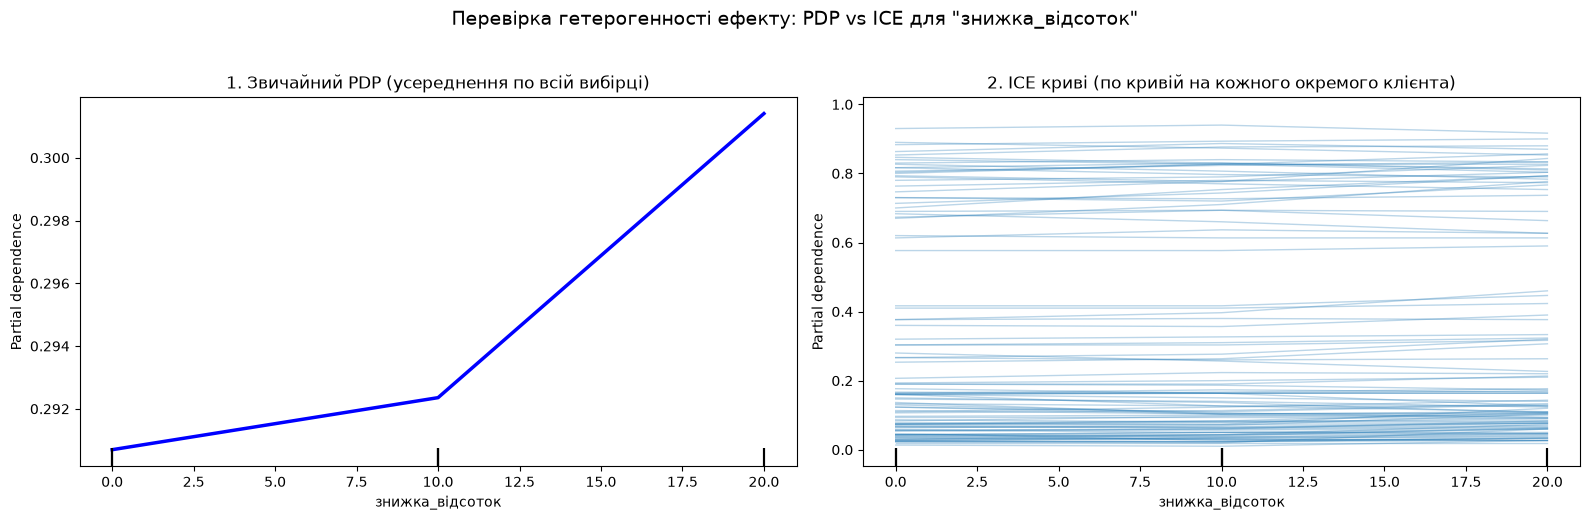

In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
PartialDependenceDisplay.from_estimator(
    estimator=model,
    X=FINAL_X,
    features=['знижка_відсоток'],
    kind='average',
    ax=axes[0],
    line_kw={'color': 'blue', 'linewidth': 2.5}
)
axes[0].set_title('1. Звичайний PDP (усереднення по всій вибірці)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)
PartialDependenceDisplay.from_estimator(
    estimator=model,
    X=FINAL_X,
    features=['знижка_відсоток'],
    kind='individual',
    subsample=100,             
    random_state=SEED,
    ax=axes[1],
    ice_lines_kw={'alpha': 0.3, 'linewidth': 1}
)
axes[1].set_title('2. ICE криві (по кривій на кожного окремого клієнта)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Перевірка гетерогенності ефекту: PDP vs ICE для "знижка_відсоток"', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

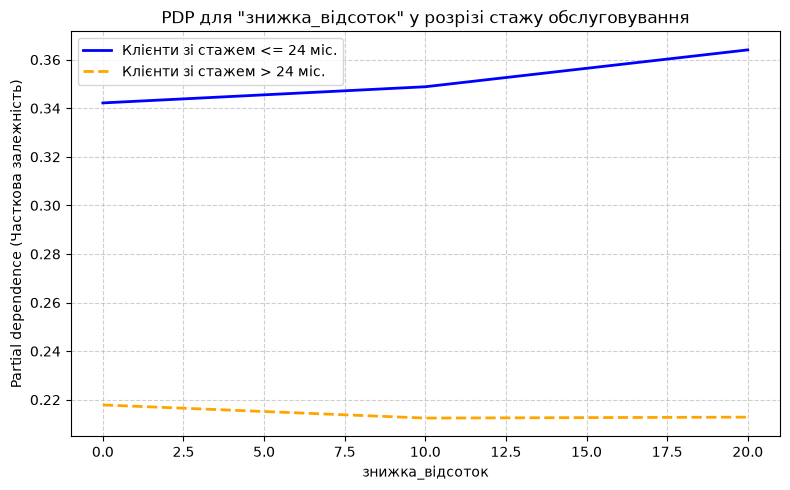

In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
mask_new = FINAL_X['місяців_обслуговування'] <= 24
mask_old = FINAL_X['місяців_обслуговування'] > 24
pdp_new = partial_dependence(
    estimator=model,
    X=FINAL_X[mask_new],
    features=['знижка_відсоток'],
    kind='average'
)
pdp_old = partial_dependence(
    estimator=model,
    X=FINAL_X[mask_old],
    features=['знижка_відсоток'],
    kind='average'
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    pdp_new['grid_values'][0], 
    pdp_new['average'][0], 
    label='Клієнти зі стажем <= 24 міс.', 
    color='blue', 
    linewidth=2
)
ax.plot(
    pdp_old['grid_values'][0], 
    pdp_old['average'][0], 
    label='Клієнти зі стажем > 24 міс.', 
    color='orange', 
    linewidth=2, 
    linestyle='--'
)
ax.set_title('PDP для "знижка_відсоток" у розрізі стажу обслуговування', fontsize=12)
ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('Partial dependence (Часткова залежність)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
df_emp = FINAL_X.copy()
df_emp['target'] = y
df_emp['група_стажу'] = np.where(
    df_emp['місяців_обслуговування'] <= 24, 
    'Стаж <= 24 міс.', 
    'Стаж > 24 міс.'
)
df_emp['знижка_діапазон'] = pd.qcut(df_emp['знижка_відсоток'], q=5, duplicates='drop')
pivot_churn = df_emp.pivot_table(
    index='знижка_діапазон',
    columns='група_стажу',
    values='target',
    aggfunc=['mean', 'count']
)

new_columns = []
for metric, group in pivot_churn.columns:
    label = 'Частка відтоку' if metric == 'mean' else 'Кількість клієнтів'
    new_columns.append(f"{group} ({label})")

pivot_churn.columns = new_columns
for col in pivot_churn.columns:
    if 'Частка відтоку' in col:
        pivot_churn[col] = (pivot_churn[col] * 100).round(2).astype(str) + '%'

print("Емпірична частка відтоку та розмір груп за інтервалами знижки:")
display(pivot_churn)

Емпірична частка відтоку та розмір груп за інтервалами знижки:


,Стаж <= 24 міс. (Частка відтоку),Стаж > 24 міс. (Частка відтоку),Стаж <= 24 міс. (Кількість клієнтів),Стаж > 24 міс. (Кількість клієнтів)
знижка_діапазон,,,,
"(-0.001, 10.0]",34.46%,20.39%,505,358
"(10.0, 20.0]",42.93%,10.79%,198,139


In [45]:
INTERACTION_FOUND = 'для клієнтів зі стажем до 2 років більша знижка супроводжується зростанням відтоку (це можуть бути реактивні або промо-клієнти), а для клієнтів зі стажем понад 2 роки знижка діє ефективно і зменшує відтік удвічі'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'припинити надання знижок новим клієнтам та перенаправити це на утримання старих'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

для клієнтів зі стажем до 2 років більша знижка супроводжується зростанням відтоку (це можуть бути реактивні або промо-клієнти), а для клієнтів зі стажем понад 2 роки знижка діє ефективно і зменшує відтік удвічі
припинити надання знижок новим клієнтам та перенаправити це на утримання старих


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['preprocessor']
clf = model.named_steps['classifier']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 39)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

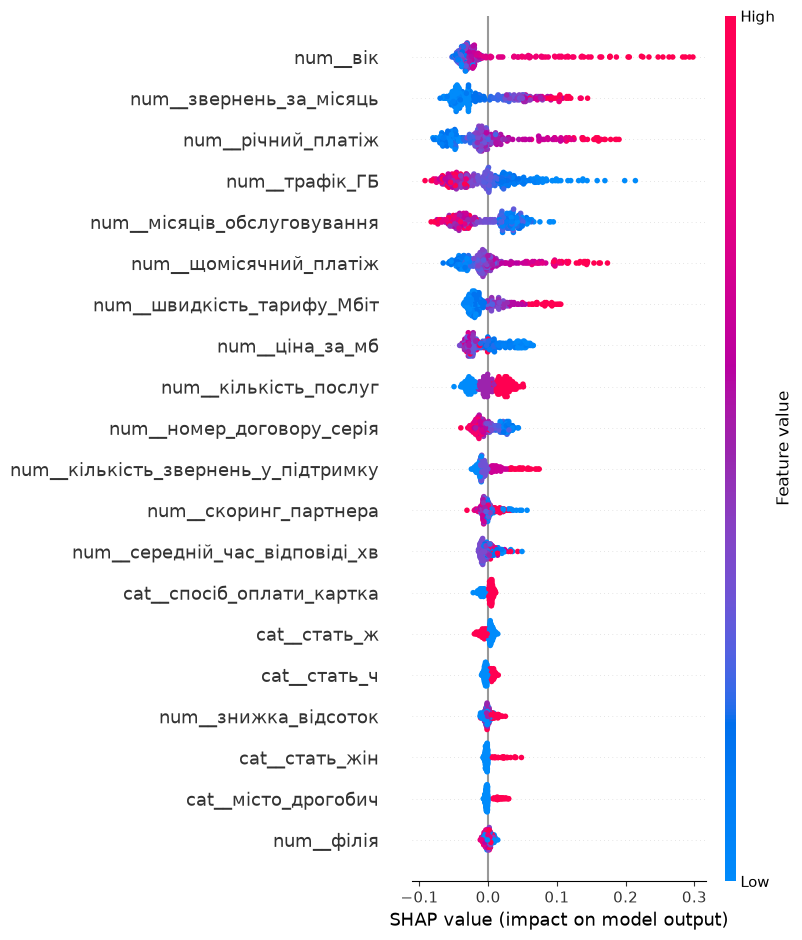

In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
shap_vals_client = sv1[idx]
top_4_idx = np.argsort(np.abs(shap_vals_client))[::-1][:4]
for i, feature_idx in enumerate(top_4_idx, 1):
    feat_name = feat_names[feature_idx]
    shap_val = shap_vals_client[feature_idx]
    print(f"{i}. {feat_name}: {shap_val:+.4f}")

ризик клієнта: 0.883
1. num__річний_платіж: +0.1537
2. num__щомісячний_платіж: +0.1338
3. num__швидкість_тарифу_Мбіт: +0.0824
4. num__ціна_за_мб: +0.0613


In [49]:
EXPLANATION_FOR_MANAGER = 'найбільше на ризик впливає сама ціна за тариф, а також швидкість самого інтернету за тарифом. клієнт не дуже задоволений, скільки він оплачує та відповідно, скільки він за це отримує'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

найбільше на ризик впливає сама ціна за тариф, а також швидкість самого інтернету за тарифом. клієнт не дуже задоволений, скільки він оплачує та відповідно, скільки він за це отримує


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = 'це характеристика людини, ми не можемо її змінити'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — це характеристика людини, ми не можемо її змінити


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",щомісячний_платіж,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'модель каже, що якщо клієнт має більше звернень у підтримку, є більший ризик розірвання угоди. Ми не можемо просто так зменшити звернення, які надходять в підтримку, потрібно оперативно вирішувати проблеми клієнтів, і тоді звернення зменшаться самостійно'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

модель каже, що якщо клієнт має більше звернень у підтримку, є більший ризик розірвання угоди. Ми не можемо просто так зменшити звернення, які надходять в підтримку, потрібно оперативно вирішувати проблеми клієнтів, і тоді звернення зменшаться самостійно


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
probs_te = model.predict_proba(Xte)[:, 1]
top_100_idx = np.argsort(probs_te)[::-1][:TOP_N]
actual_churn_in_top100 = yte.iloc[top_100_idx].sum()
precision_top100 = actual_churn_in_top100 / TOP_N
baseline_churn_rate = yte.mean()
lift = precision_top100 / baseline_churn_rate
print(f"Кількість реального відтоку серед Top-{TOP_N}: {actual_churn_in_top100} із {TOP_N}")
print(f"Частка відтоку в Top-{TOP_N} (Precision@{TOP_N}): {precision_top100:.2%}")
print(f"Базова частка відтоку по всій вибірці (Random): {baseline_churn_rate:.2%}")
print(f"Lift моделі: {lift:.2f}x")

Кількість реального відтоку серед Top-100: 61 із 100
Частка відтоку в Top-100 (Precision@100): 61.00%
Базова частка відтоку по всій вибірці (Random): 28.89%
Lift моделі: 2.11x


In [54]:
LIFT_MEANING = 'можемо охопити більше клієнтів, які мають вищий ризик, а саме в 2 рази більше, якщо порівнювати з випадковістю'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

можемо охопити більше клієнтів, які мають вищий ризик, а саме в 2 рази більше, якщо порівнювати з випадковістю


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_05.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Обрав AUC. Дані мають дизбаланс у розподілі класів+нам потрібно обирати клієнтів з найбільшим ризиком. Точність дорівнювала б приблизно 70%
2. код_причини_закриття - після розірвання договору, дата_розірвання - в момент розірвання договору, кількість_дзвінків_утримання - під час або після дзвінка. Останню не знайшов детектор, бо значення заповнене всюди, і детектор не міг прив'язати існування цього значення до якогось з класів
3. 0.827+-0.018, при такому розкиді порівняння двох моделей, що відрізняються на 0.004, ця різниця є шумом
4. 0.805 для передбачення джерела, я б не довіряв цій моделі в іншій філії без додаткового навчання.
5. нові ознаки трохи менше, ніж складніша модель (0.825 та 0.829 відповідно), але за часом нові ознаки були набагато швидші у виконанні (4.5с для складної моделі на 100 навчань, менше 1 секунди на виконання тренування з новими ознаками)
6. щомісячний_платіж, це є коректна поведінка, бо дерева надають перевагу неперервним числовим ознакам з високою кардинальністю, можливість робити багато поділів штучно роздуває показник зменшення неоднорідності, навіть якщо ознака дублює інші
7. щомісячний_платіж та річний_платіж, важливість поділилась між ними, це не вада, бо перестановочна важливість показує, наскільки погіршиться модель при втраті конкретного стовпчика. Якщо один стовпчик перемішано, модель продовжує бере збережену інформацію з його дубліката
8. трафік_ГБ, до 250ГБ іде стрімке спадання, після 250ГБ переходить на плато, без втручання логістична регресія продовжувала б спадати.
9. PDP для знижка_відсоток показує помірне зростання ризику відтоку при збільшенні знижки, ICE показує індивідуальні криві, які мають різну поведінку залежно від базового ризику
10. вік (втрутитись не можемо взагалі), модель може використовувати цю ознаку (що показує кореляцію), але саме причиною ми це назвати не можемо
11. використовуючи модель (яка дає lift 2.11x), можна знайти 53 клієнти на межі утримання, замість 25 клієнтів при випадковому. Як застереження я б перестав давати знижки новим клієнтам, а замість цього пропонував б клієнтам з більшим стажем бонуси за їхню лояльність

Декларація про використання ШІ: Використовував Gemini для допомоги з написанням коду для деяких завдань. Для формування звіту та висновків ШІ не використовувався.
'''
print(REPORT)


1. Обрав AUC. Дані мають дизбаланс у розподілі класів+нам потрібно обирати клієнтів з найбільшим ризиком. Точність дорівнювала б приблизно 70%
2. код_причини_закриття - після розірвання договору, дата_розірвання - в момент розірвання договору, кількість_дзвінків_утримання - під час або після дзвінка. Останню не знайшов детектор, бо значення заповнене всюди, і детектор не міг прив'язати існування цього значення до якогось з класів
3. 0.827+-0.018, при такому розкиді порівняння двох моделей, що відрізняються на 0.004, ця різниця є шумом
4. 0.805 для передбачення джерела, я б не довіряв цій моделі в іншій філії без додаткового навчання.
5. нові ознаки трохи менше, ніж складніша модель (0.825 та 0.829 відповідно), але за часом нові ознаки були набагато швидші у виконанні (4.5с для складної моделі на 100 навчань, менше 1 секунди на виконання тренування з новими ознаками)
6. щомісячний_платіж, це є коректна поведінка, бо дерева надають перевагу неперервним числовим ознакам з високою кардина

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.